本 notebook 是 [M02.3 概率论与信息论](../notes/03-probability-information.qmd) 的实例讲解。

1. 1. 贝叶斯反演与基础发生率
2. 2. 联合高斯、边缘与条件
3. 3. 变量变换与 Jacobian
4. 4. 熵、交叉熵、KL 与互信息

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.integrate import quad
from scipy.stats import entropy, multivariate_normal, norm

from semiai.plotting import BLUE, GRAY, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 贝叶斯反演与基础发生率

同一个检测器遇到不同先验发生率时，阳性样本中的真实阳性比例会改变。用公式和合成频数计算同一个量。

In [2]:
prevalence = 0.01
sensitivity = 0.95
false_positive = 0.02
posterior = (
    sensitivity * prevalence / (sensitivity * prevalence + false_positive * (1 - prevalence))
)
truth = rng.random(400000) < prevalence
positive = rng.random(len(truth)) < np.where(truth, sensitivity, false_positive)
print("解析阳性预测值:", posterior)
print("模拟阳性预测值:", truth[positive].mean())
print("阳性总数:", positive.sum())

解析阳性预测值: 0.3242320819112628
模拟阳性预测值: 0.32524478501489995
阳性总数: 11745


读法：灵敏度是给定真实类别后的检测概率，阳性预测值是给定检测结果后的类别概率；二者不能交换，发生率进入分母的混合概率。

## 2. 联合高斯、边缘与条件

用分块协方差计算条件分布，并比较相关系数改变后的条件不确定性。

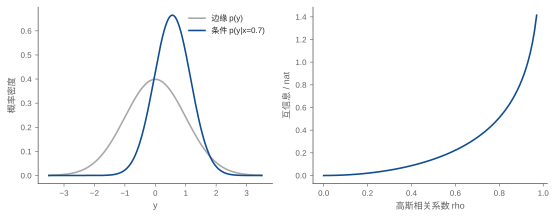

条件均值（解析/采样）: 0.5599999999999999 0.5588373333086766
条件方差（解析/采样）: 0.3599999999999999 0.3628960346536308


In [3]:
x = np.linspace(-3.5, 3.5, 300)
rho = 0.8
observed = 0.7
conditional_mean = rho * observed
conditional_std = np.sqrt(1 - rho**2)
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.1))
axes[0].plot(x, norm.pdf(x), color=GRAY, label="边缘 p(y)")
axes[0].plot(x, norm.pdf(x, conditional_mean, conditional_std), color=BLUE, label="条件 p(y|x=0.7)")
axes[0].set(xlabel="y", ylabel="概率密度")
axes[0].legend()
rs = np.linspace(0, 0.97, 100)
axes[1].plot(rs, -0.5 * np.log1p(-(rs**2)), color=BLUE)
axes[1].set(xlabel="高斯相关系数 rho", ylabel="互信息 / nat")
fig.tight_layout()
plt.show()

Sigma = np.array([[1.0, rho], [rho, 1.0]])
mu_y = Sigma[1:, :1] @ np.linalg.solve(Sigma[:1, :1], np.array([observed]))
var_y = Sigma[1:, 1:] - Sigma[1:, :1] @ np.linalg.solve(Sigma[:1, :1], Sigma[:1, 1:])
conditional_samples = rng.normal(mu_y.item(), np.sqrt(var_y.item()), size=100000)
print("条件均值（解析/采样）:", mu_y.item(), conditional_samples.mean())
print("条件方差（解析/采样）:", var_y.item(), conditional_samples.var())
assert np.allclose(mu_y.item(), rho * observed)
assert np.allclose(var_y.item(), 1 - rho**2)

读法：条件化同时改变均值和协方差；边缘化只是选取相应的均值与协方差子块。高斯条件协方差在这里与观测数值无关。

## 3. 变量变换与 Jacobian

把标准高斯通过指数变换映射到正数域。检查带与不带 Jacobian 的密度积分。

In [4]:
def correct(y):
    return norm.pdf(np.log(y)) / y


def wrong(y):
    return norm.pdf(np.log(y))


a = quad(correct, 0, np.inf)[0]
b = quad(wrong, 0, np.inf)[0]
print("正确密度积分:", a, "遗漏 Jacobian 的积分:", b)
assert abs(a - 1) < 1e-7

正确密度积分: 0.9999999999942906 遗漏 Jacobian 的积分: 1.6487212706999776


读法：密度必须对输出坐标积分为 1。变换改变了局部体积，乘上逆变换 Jacobian 的绝对行列式才能保持概率质量。

## 4. 熵、交叉熵、KL 与互信息

在离散分布上验证交叉熵分解，再以联合高斯检验互信息的解析表达式。

In [5]:
p = np.array([0.8, 0.2])
q = np.array([0.6, 0.4])
H = -np.sum(p * np.log(p))
CE = -np.sum(p * np.log(q))
KL = entropy(p, q)
print(pd.DataFrame({"quantity": ["H(p)", "cross entropy", "KL(p||q)"], "nat": [H, CE, KL]}))
assert np.allclose(CE, H + KL)
xy = rng.multivariate_normal([0, 0], [[1, 0.8], [0.8, 1]], size=100000)
logratio = multivariate_normal.logpdf(xy, mean=[0, 0], cov=[[1, 0.8], [0.8, 1]]) - norm.logpdf(
    xy
).sum(axis=1)
print("高斯互信息（解析/Monte Carlo）:", -0.5 * np.log(1 - 0.8**2), logratio.mean())

        quantity       nat
0           H(p)  0.500402
1  cross entropy  0.591919
2       KL(p||q)  0.091516
高斯互信息（解析/Monte Carlo）: 0.5108256237659908 0.5112723329780093


读法：KL 衡量方向明确的分布差异，不是距离；互信息是联合分布相对于边缘乘积的 KL，因此刻画的不只是线性相关。

## 小结

联合分布是条件化和边缘化的共同起点。高斯分块公式把观测更新转化成线性代数，Jacobian 保持坐标变换下的概率质量。熵描述一个分布的不确定性，交叉熵和 KL 比较分布，互信息比较依赖与独立。